In [1]:
! pip install -q ultralytics
! pip install -q wandb
! pip install tensorflow.keras

In [2]:
import os
import cv2
import time
import random
import imutils
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm
from termcolor import colored
from ultralytics import YOLO
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
warnings.filterwarnings('ignore')
plt.style.use('fivethirtyeight')
sns.set_style('darkgrid')

In [6]:
x=[]
y=[]

folder_path = '/content/drive/MyDrive/mypelak/chars'
for root, dirs, files in os.walk(folder_path):

    for dir_name in dirs:

        folder_path = f'/content/drive/MyDrive/mypelak/chars/{dir_name}/2'
        for root, dirs, files in os.walk(folder_path):

            for file in files:
                y.append(dir_name)
                x.append(cv2.imread(os.path.join(root, file),0))

In [7]:
print(len(x))
print(type(x))

print(len(y))
print(type(y))

56385
<class 'list'>
56385
<class 'list'>


In [8]:
#plt.imshow(x[10])
#plt.title(y[10])

In [9]:
xx = []
yy = []

for img, label in zip(x, y):
    if img is None or img.size == 0:
        continue
    img2 = cv2.resize(img, (10, 10))
    img3 = img2.flatten()
    xx.append(img3 / 255)
    yy.append(label)

x2 = np.array(xx)
y2 = np.array(yy)

print("x2:", x2.shape)
print("y2:", y2.shape)

x2: (56383, 100)
y2: (56383,)


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    x2, y2,
    test_size=0.2,
    random_state=42,
    stratify=y2
)

print("Train shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)

Train shape: (45106, 100) (45106,)
Test shape: (11277, 100) (11277,)


In [ ]:
def preprocess(img_input) :
  img_input = cv2.cvtColor(img_input, cv2.COLOR_BGR2GRAY)
  imgm=cv2.medianBlur(img_input,3)
  th = cv2.adaptiveThreshold(imgm,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,11,5)

  return th

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
knn=KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
def predict_text(img_input):
  img2=cv2.resize(img_input,(10,10))
  img3=np.reshape(img2,(-1,100))/255
  return knn.predict(img3)

In [ ]:
model = YOLO("/content/drive/MyDrive/mypelak/latin/models/YOLOv8m_Iran_license_plate_detection.pt")

In [ ]:
def cut(img):

    img = imutils.resize(img, width=800)
    results = model.predict(img, conf=0.4, verbose=False)

    for r in results:
        boxes = r.boxes
        for box in boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0])

            plate_img = img[y1:y2, x1:x2]
            return plate_img

(np.float64(-0.5), np.float64(1023.5), np.float64(1023.5), np.float64(-0.5))

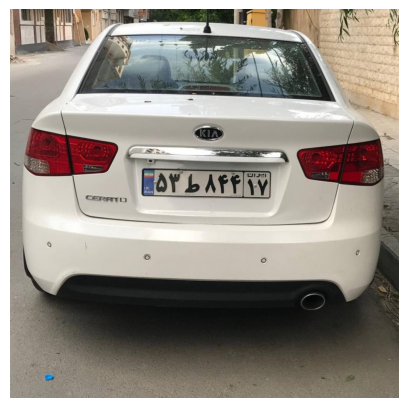

In [ ]:
img_test=cv2.imread("/content/drive/MyDrive/mypelak/8.jpg")[...,::-1]
plt.imshow(img_test)
plt.axis("off")

(np.float64(-0.5), np.float64(278.5), np.float64(73.5), np.float64(-0.5))

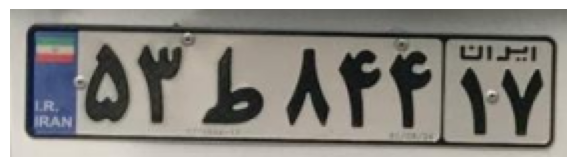

In [ ]:
img=cut(img_test)
plt.imshow(img)
plt.axis("off")

(np.float64(-0.5), np.float64(278.5), np.float64(73.5), np.float64(-0.5))

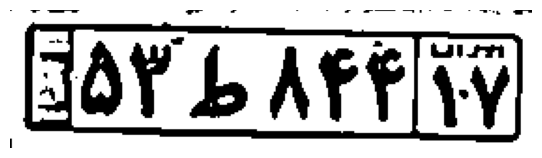

In [ ]:
plt.figure(figsize=(6,5))
img = preprocess(img)
plt.imshow(img, cmap="gray")
plt.axis("off")

In [ ]:
print(img.shape)
img_CC=img.copy()

(74, 279)


In [ ]:
gray = img
img_BGR = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

blur = cv2.GaussianBlur(gray, (3,3), 0)
edges = cv2.Canny(blur, 50, 150)

contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

max_area = 0
best_box = None

for cnt in contours:
    rect = cv2.minAreaRect(cnt)
    (cx,cy), (w,h), angle = rect
    area = w*h
    if area > max_area and w > h and w/h > 2:
        max_area = area
        best_box = rect

if best_box:
    box = cv2.boxPoints(best_box)
    box = np.int32(box)

    box = sorted(box, key=lambda x: (x[1], x[0]))
    if box[0][0] > box[1][0]:
        box[0], box[1] = box[1], box[0]
    if box[2][0] < box[3][0]:
        box[2], box[3] = box[3], box[2]

    w = int(best_box[1][0])
    h = int(best_box[1][1])
    dst_pts = np.array([[0,0],[w-1,0],[w-1,h-1],[0,h-1]], dtype="float32")

    M = cv2.getPerspectiveTransform(np.float32(box), dst_pts)
    warped = cv2.warpPerspective(img_BGR, M, (w,h))
    box= np.array(box)
    cv2.drawContours(img_BGR, [box.reshape(-1,1,2)], 0, (0,255,0), 3)

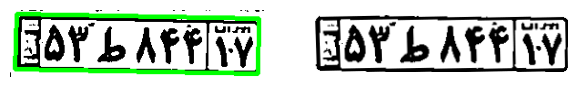

In [ ]:
plt.subplot(121); plt.imshow(cv2.cvtColor(img_BGR, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.subplot(122); plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.show()

In [ ]:
img = cv2.cvtColor(warped, cv2.COLOR_RGB2GRAY)
print("img: ",img.shape)
print("CC: ",img_CC.shape)

img:  (60, 266)
CC:  (74, 279)


5


(np.float64(-0.5), np.float64(175.5), np.float64(37.5), np.float64(-0.5))

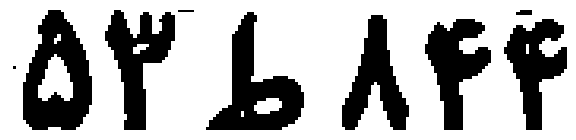

In [ ]:
if img.shape[0] > 60 and img.shape[1] > 200:
  img_Final = img[13:img.shape[0]-5,img.shape[1]//9:img.shape[1]-8]
  print("1")

elif 30 < img.shape[0] < 60 and 170 < img.shape[1] < 200 :
  img_Final = img[5:img.shape[0]-5,5:img.shape[1]-5]
  print("2")


elif img.shape[0] > 60 and img.shape[1] < 200 :
  img_Final = img[13:img.shape[0]-5,5:img.shape[1]-5]
  print("3")


elif 50 <img.shape[0] < 60 and img.shape[1] > 200 :
  img_Final = img[5:img.shape[0]-5,img.shape[1]//8:img.shape[1]-5]
  print("4")


else :
  img_Final = img_CC[img_CC.shape[0]//4:img_CC.shape[0]- img_CC.shape[0]//4 , img_CC.shape[1]//8:img_CC.shape[1]-img_CC.shape[1]//4]
  print("5")



plt.imshow(img_Final, cmap="gray"); plt.axis("off")

In [ ]:
img_Final.shape

(38, 176)

In [ ]:
new_height = img_Final.shape[0] + 50
new_width = img_Final.shape[1] + 40

white_bg = np.ones((new_height, new_width), dtype='uint8') * 255

y_offset = (new_height - img_Final.shape[0]) // 2
x_offset = (new_width - img_Final.shape[1]) // 2

white_bg[y_offset+10:y_offset+10+img_Final.shape[0], x_offset:x_offset+img_Final.shape[1]] = img_Final
result = white_bg

(np.float64(-0.5), np.float64(215.5), np.float64(87.5), np.float64(-0.5))

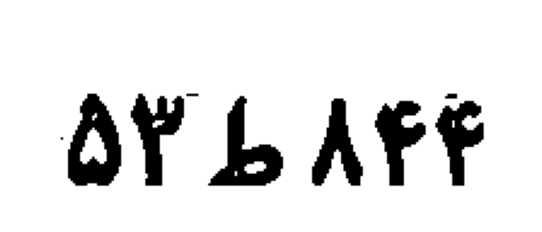

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(result, cmap="gray")
plt.axis("off")

In [ ]:
kernel = np.ones((3, 3), np.uint8)
result = cv2.morphologyEx(result, cv2.MORPH_OPEN, kernel)

(np.float64(-0.5), np.float64(215.5), np.float64(87.5), np.float64(-0.5))

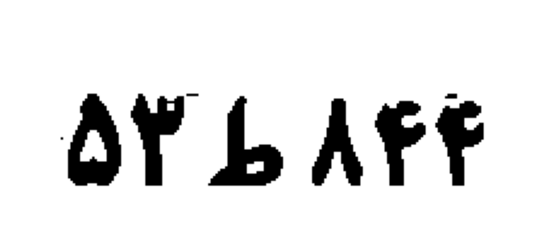

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(result, cmap="gray")
plt.axis("off")

In [ ]:
result.shape

(88, 216)

(np.float64(-0.5), np.float64(215.5), np.float64(87.5), np.float64(-0.5))

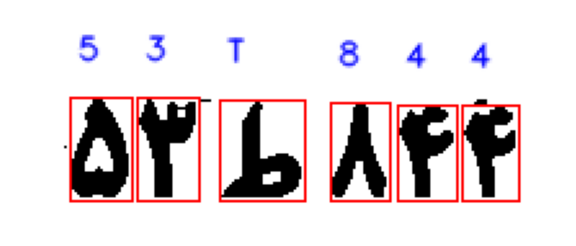

In [ ]:
cont, hie=cv2.findContours(result, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
result2=cv2.cvtColor(result, cv2.COLOR_GRAY2BGR)

if 90 < result.shape[0] and 200 < result.shape[1]  :
  min_ = 240
elif 90 > result.shape[0] or 200 > result.shape[1]  :
  min_ = 155
s = []
p = []
for i in cont:
  if cv2.contourArea(i)>min_ and cv2.contourArea(i)<900:
    [x,y,w,h]=cv2.boundingRect(i)
    cv2.rectangle(result2,(x,y),(x+w,y+h),(255,0,0),1)
    cropped = result[y:y+h, x:x+w]

    pre = predict_text(cropped)

    cv2.putText(result2, str(pre[0]), (x+3, y-15), cv2.FONT_HERSHEY_SIMPLEX, 0.40, (0, 0, 255), 1, cv2.LINE_AA)

    s.append(cropped)
    p.append(pre)

plt.imshow(result2)
plt.axis("off")